# Image Segmentation with a U-Net-like Architecture
---
At the end of this laboratory, you would get familiarized with:

*   Segmentation using UNet
*   Understand the evaluation metrics
*   Importance of data annotations

**Remember this is a graded exercise.**

*   For every plot, make sure you provide appropriate titles, axis labels, legends, wherever applicable.
*   Create reusable functions where ever possible, so that the code could be reused at different places.
*   Add sufficient comments and explanations wherever necessary.
*   **Once you have the code completed, use GPU to train model faster.**
* This lab must be worked in pairs. Make sure that when you submit your lab you change the name to: **07_lab_Student1FullName_Student2FullName.ipynb**


---

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [6]:
DATA_DIR = "/content/drive/MyDrive/covid19-ct-scans"

In [19]:
from tensorflow.keras import layers

def get_model(img_size, num_classes, n_channels):
    inputs = keras.Input(shape=img_size + (n_channels,))

    ### [First half of the network: downsampling inputs] ###

    # Entry block
    x = layers.Conv2D(32, 3, strides=2, padding="same")(inputs)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)

    previous_block_activation = x  # Set aside residual

    # Blocks 1, 2, 3 are identical apart from the feature depth.
    for filters in [64, 128, 256]:
        x = layers.Activation("relu")(x)
        x = layers.SeparableConv2D(filters, 3, padding="same")(x)
        x = layers.BatchNormalization()(x)

        x = layers.Activation("relu")(x)
        x = layers.SeparableConv2D(filters, 3, padding="same")(x)
        x = layers.BatchNormalization()(x)

        x = layers.MaxPooling2D(3, strides=2, padding="same")(x)

        # Project residual
        residual = layers.Conv2D(filters, 1, strides=2, padding="same")(
            previous_block_activation
        )
        x = layers.add([x, residual])  # Add back residual
        previous_block_activation = x  # Set aside next residual

    ### [Second half of the network: upsampling inputs] ###

    for filters in [256, 128, 64, 32]:
        x = layers.Activation("relu")(x)
        x = layers.Conv2DTranspose(filters, 3, padding="same")(x)
        x = layers.BatchNormalization()(x)

        x = layers.Activation("relu")(x)
        x = layers.Conv2DTranspose(filters, 3, padding="same")(x)
        x = layers.BatchNormalization()(x)

        x = layers.UpSampling2D(2)(x)

        # Project residual
        residual = layers.UpSampling2D(2)(previous_block_activation)
        residual = layers.Conv2D(filters, 1, padding="same")(residual)
        x = layers.add([x, residual])  # Add back residual
        previous_block_activation = x  # Set aside next residual

    # Add a per-pixel classification layer
    outputs = layers.Conv2D(num_classes, 3, activation="softmax", padding="same")(x)

    # Define the model
    model = keras.Model(inputs, outputs)
    return model

*  We will use the get_model method from the tutorial to build the model

# U-net with Covid-19 CT scans dataset

**About the dataset:** This dataset contains 20 CT scans of patients diagnosed with COVID-19 as well as segmentations of lungs and infections made by experts. This dataset provides a CT scan, a lung mask, an infection mask and a lung and infection mask made by experts. We are going to focus on the infection mask as we want to segment this section from a CT.


**1. Load the metadata file provided and understand its content (metadata.csv) (0.5 points)**

In [4]:
import os
import cv2
import numpy as np
import pandas as pd
import nibabel as nib
import matplotlib.pyplot as plt
import tensorflow as tf
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
from sklearn.metrics import jaccard_score
from sklearn.model_selection import train_test_split
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.utils import Sequence
from tqdm import tqdm

In [7]:
#solution
metadata = pd.read_csv(os.path.join(DATA_DIR, "metadata.csv"))
print("Shape:", metadata.shape)
print("Columns:", list(metadata.columns))
print("Missing values:\n", metadata.isna().sum())
print("Volumes per source:",
      metadata["ct_scan"].str.contains("coronacases").sum(), "coronacases /",
      metadata["ct_scan"].str.contains("radiopaedia").sum(), "radiopaedia")
metadata.head()

Shape: (20, 4)
Columns: ['ct_scan', 'lung_mask', 'infection_mask', 'lung_and_infection_mask']
Missing values:
 ct_scan                    0
lung_mask                  0
infection_mask             0
lung_and_infection_mask    0
dtype: int64
Volumes per source: 10 coronacases / 10 radiopaedia


,ct_scan,lung_mask,infection_mask,lung_and_infection_mask
0,../input/covid19-ct-scans/ct_scans/coronacases...,../input/covid19-ct-scans/lung_mask/coronacase...,../input/covid19-ct-scans/infection_mask/coron...,../input/covid19-ct-scans/lung_and_infection_m...
1,../input/covid19-ct-scans/ct_scans/coronacases...,../input/covid19-ct-scans/lung_mask/coronacase...,../input/covid19-ct-scans/infection_mask/coron...,../input/covid19-ct-scans/lung_and_infection_m...
2,../input/covid19-ct-scans/ct_scans/coronacases...,../input/covid19-ct-scans/lung_mask/coronacase...,../input/covid19-ct-scans/infection_mask/coron...,../input/covid19-ct-scans/lung_and_infection_m...
3,../input/covid19-ct-scans/ct_scans/coronacases...,../input/covid19-ct-scans/lung_mask/coronacase...,../input/covid19-ct-scans/infection_mask/coron...,../input/covid19-ct-scans/lung_and_infection_m...
4,../input/covid19-ct-scans/ct_scans/coronacases...,../input/covid19-ct-scans/lung_mask/coronacase...,../input/covid19-ct-scans/infection_mask/coron...,../input/covid19-ct-scans/lung_and_infection_m...


**2. Load the image dataset into your notebook (data_covid19CT_segmentation folder) (2.5 points)**

*Loading nii files: The image files come on a .nii format, this format is created by Neuroimaging Informatics Technology Initiative. It is commonly used to store magnetic resonance imaging (MRI) data. We are providing you a function to read the images:*

In [8]:
# Function provided to read the different .nii files
import nibabel as nib #for loading nii files
import os
def read_nii(datapath, filepath):
    # metadata paths look like "../input/covid19-ct-scans/ct_scans/xxx.nii" (Kaggle layout)
    filepath = filepath.replace("../input/covid19-ct-scans/", "")
    filepath = os.path.join(datapath, filepath)

    ct_scan = nib.load(filepath)
    array   = ct_scan.get_fdata()

    # rotate the 2D slice so it is displayed upright
    array   = np.rot90(np.array(array))
    return array


**2.1 Read all the nii files for the second observation of the csv file (ct scan, lung, infection and the lung and infection mask as well). Print the ct scan dimensions.**

In [10]:
#solution

# second observation (index 1)
row = metadata.iloc[1]
volumes = {}
for col in metadata.columns:
    try:
        volumes[col] = read_nii(DATA_DIR, row[col])
    except FileNotFoundError:
        # The Drive copy only has ct_scans/ and infection_mask/
        print(f"[skipped] {col}: folder not present in the Drive copy")

for name, vol in volumes.items():
    print(f"{name:25s} shape={vol.shape}  dtype={vol.dtype}  min={vol.min():.1f}  max={vol.max():.1f}")

ct, infection = volumes["ct_scan"], volumes["infection_mask"]
print("\nCT scan dimensions:", ct.shape)

[skipped] lung_mask: folder not present in the Drive copy
[skipped] lung_and_infection_mask: folder not present in the Drive copy
ct_scan                   shape=(512, 512, 200)  dtype=float64  min=-1023.0  max=9567.0
infection_mask            shape=(512, 512, 200)  dtype=float64  min=0.0  max=1.0

CT scan dimensions: (512, 512, 200)


Explain the shape of the observation loaded. What does the third dimension represents?

**Solution**

The array is 3D: `(height, width, n_slices)`. Each `.nii` file is a whole *volume*: a stack of 2D axial
cross-sections of the chest. The third dimension is therefore the **slice index** along the body axis (top to bottom of the
lungs), not a colour channel. The number of slices differs per patient, which is why one patient yields hundreds of 2D training
images. Print `np.unique(infection)` to confirm the infection mask is binary (0 = healthy tissue, 1 = infection).

...

**2.2 Visualizing input image and corresponding segmentation mask**

Produce two plots side by side:
*   First plot should be the visualization of CT scan with index 30 from the ct sample read in the previous step.
*   Second plot should show the corresponding mask overlayed on the original image.
*   Use cmap = 'bone', this palette is a grayscale colormap that is commonly used for representing data as shades of gray.

Make sure to add titles.

In [12]:
#solution

def plot_slice_with_mask(ct_vol, mask_vol, idx=30):
    """Left: CT slice. Right: same slice with the infection mask overlaid in red."""
    ct_slice, mask_slice = ct_vol[:, :, idx], mask_vol[:, :, idx]
    fig, axes = plt.subplots(1, 2, figsize=(11, 5))

    axes[0].imshow(ct_slice, cmap="bone")
    axes[0].set_title(f"CT scan, slice {idx}")

    axes[1].imshow(ct_slice, cmap="bone")
    overlay = np.ma.masked_where(mask_slice == 0, mask_slice)         # hide the zeros
    axes[1].imshow(overlay, cmap=ListedColormap(["red"]), alpha=0.6)
    axes[1].set_title(f"Infection mask overlaid, slice {idx}")
    axes[1].legend(handles=[Patch(color="red", alpha=0.6, label="Infection")], loc="lower right")

    for ax in axes:
        ax.set_xlabel("x (pixels)"); ax.set_ylabel("y (pixels)")
    plt.tight_layout(); plt.show()

**2.3 Print the structure/shape of one CT image on the dataset.**
* How many color channels does this image has? How does this impact the modeling?

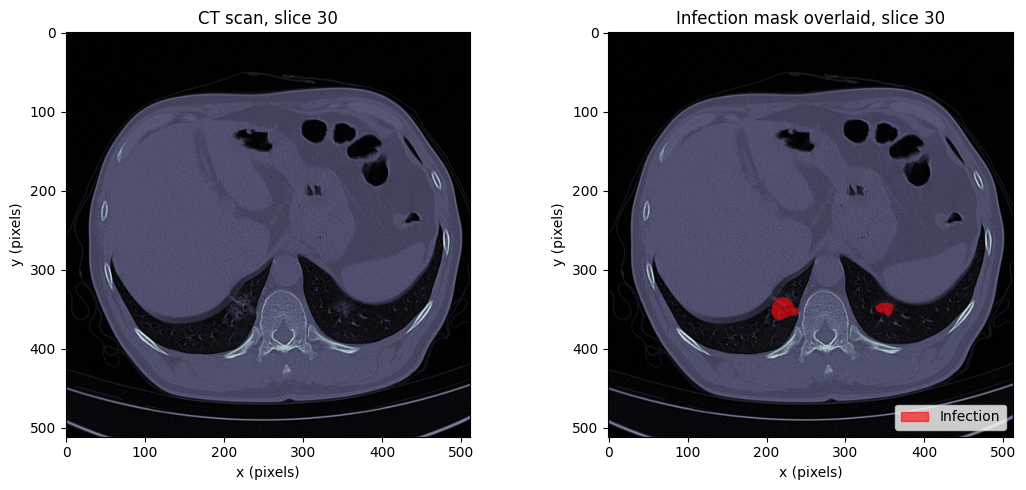

Infection pixels in slice 30: 1011
Slice with most infection: 93


In [13]:
#solution

plot_slice_with_mask(ct, infection, idx=30)
print("Infection pixels in slice 30:", int((infection[:, :, 30] > 0).sum()))
print("Slice with most infection:", int(np.argmax((infection > 0).sum(axis=(0, 1)))))

In [14]:
one_slice = ct[:, :, 30]
print("One CT image shape:", one_slice.shape)

One CT image shape: (512, 512)


**Solution**

One slice is 2D: `(H, W)`, i.e. **1 channel** (grayscale, one intensity value per pixel; CT intensities are
radiodensity, not colour). The Oxford Pets tutorial used RGB images with 3 channels. Here we must add an explicit channel axis
so the input is `(H, W, 1)` and build the network with `n_channels=1`. It also means we cannot use ImageNet-pretrained RGB weights
without replicating the channel, and the model has fewer input parameters to learn.

...

**2.4 Loading Input Images and Segmentation Masks**

*   Prepare data to train the model, use only the ct scans as your training data/features and the infection masks as the ground truth as we will focus only on this problem and not the other masks available.
*   Make sure images are resize to 128x128 so the training is faster. Use cv2 function for this.
*   Your final objects should be arrays of size: (3250,128,128,1)

Hint: You can create a for loop to go through each observation from the dataframe and read the appropriate files.
Remember that each observation has multiple slices stored.

Here is a starter code:

```python
import cv2
from tqdm import tqdm
cts = []
infections = []
img_size = (128,128)

for i in tqdm(range(len(data))):
  # Read nii for ct and infections
  for ii in range(ct.shape[dim]): #change dim to the dimension that you want to loop :)
    ct_img = cv2.resize(ct[ii], dsize = img_size,interpolation = cv2.INTER_AREA).astype('uint8')
    # Repeat process for infections
    # Append them to cts and infections

infections = np.array(infections)
cts = np.array(cts)
pritn(cts.shape)
```

In [15]:
#solution
import cv2
from tqdm import tqdm

def to_uint8(volume, low_pct=1, high_pct=99):
    """Clip outliers and rescale a whole CT volume to 0-255."""
    lo, hi = np.percentile(volume, [low_pct, high_pct])
    volume = np.clip(volume, lo, hi)
    return ((volume - lo) / (hi - lo + 1e-8) * 255).astype("uint8")

cts, infections = [], []
img_size = (128, 128)

for i in tqdm(range(len(metadata))):
    ct_vol  = to_uint8(read_nii(DATA_DIR, metadata.loc[i, "ct_scan"]))
    inf_vol = (read_nii(DATA_DIR, metadata.loc[i, "infection_mask"]) > 0).astype("uint8")
    assert ct_vol.shape == inf_vol.shape, f"CT/mask shape mismatch in row {i}"

    for ii in range(ct_vol.shape[2]):                       # loop over slices (third axis)
        cts.append(cv2.resize(ct_vol[:, :, ii], dsize=img_size, interpolation=cv2.INTER_AREA))
        infections.append(cv2.resize(inf_vol[:, :, ii], dsize=img_size, interpolation=cv2.INTER_NEAREST))

cts = np.array(cts)[..., np.newaxis]                 # (N, 128, 128, 1)
infections = np.array(infections)[..., np.newaxis]   # (N, 128, 128, 1)
print("cts:", cts.shape, cts.dtype, "| infections:", infections.shape, infections.dtype)
print("mask values:", np.unique(infections))
print("Share of infected pixels: %.2f%%" % (100 * infections.mean()))
print("Share of slices with infection: %.1f%%" % (100 * (infections.reshape(len(infections), -1).max(1) > 0).mean()))

100%|██████████| 20/20 [02:39<00:00,  7.98s/it]


cts: (3520, 128, 128, 1) uint8 | infections: (3520, 128, 128, 1) uint8
mask values: [0 1]
Share of infected pixels: 0.85%
Share of slices with infection: 52.4%


**2.5 Split into train and test, use 10% of all the images for test set. You can use sklearn function for this.**

In [16]:
#solution

X_train, X_val, y_train, y_val = train_test_split(
    cts, infections, test_size=0.1, random_state=42, shuffle=True)
print("Train:", X_train.shape, y_train.shape)
print("Test :", X_val.shape, y_val.shape)

Train: (3168, 128, 128, 1) (3168, 128, 128, 1)
Test : (352, 128, 128, 1) (352, 128, 128, 1)


**Creating the Image Generator**

*   Create an image generator class (similar to the tutorial) to iterate over the images and return a tuple corresponding to the batch number.
*   The generator should inherit from the Sequence class.
*   It should at least have \_\_init\_\_(), \_\_len\_\_() and \_\_getitem\_\_() methods.
*   The batch size, image size, image paths and mask paths should be initialized using the \_\_init\_\_ method.

We have provided you a code for this, you can change some things if you like or if it is causing you any trouble with your previous data processing. In the provided code, \_data_generation is very similar to the code for loading the nii files, where you resized and kept appending over a loop the different files. The difference comes from now using *indexes* specifying the batch you are working with. __get_item__ returns the values of the batch, get_masks returns only masks (but same logic as _data_generation).

In [17]:
import cv2
import numpy as np
from tensorflow.keras.utils import Sequence

class ImageDataGenerator(Sequence):
  def __init__(self, ct_data, infect_data, data_path, batch_size, img_size):
    self.ct_data = ct_data
    self.infect_data = infect_data
    self.data_path = data_path
    self.batch_size = batch_size
    self.img_size = img_size
    self.indexes = np.arange(len(self.ct_data))

  def __len__(self):
    return (len(self.ct_data) + self.batch_size - 1) // self.batch_size

  def __getitem__(self, index):
    start_idx = index * self.batch_size
    end_idx = min((index + 1) * self.batch_size, len(self.ct_data))
    indexes = self.indexes[start_idx:end_idx]
    return self.__data_generation(indexes)

  def __data_generation(self, indexes):
    batch_ct, batch_infect = [], []
    for i in indexes:
      ct_img = cv2.resize(self.ct_data[i], dsize=self.img_size,
                          interpolation=cv2.INTER_AREA).astype('float32') / 255.0   # <- changed
      infect_img = cv2.resize(self.infect_data[i], dsize=self.img_size,
                              interpolation=cv2.INTER_NEAREST).astype('uint8')
      batch_ct.append(ct_img[..., np.newaxis])
      batch_infect.append(infect_img[..., np.newaxis])
    return np.array(batch_ct), np.array(batch_infect)

  def get_masks(self):
    masks = []
    for i in range(len(self.ct_data)):
      infect_img = cv2.resize(self.infect_data[i], dsize=self.img_size,
                              interpolation=cv2.INTER_NEAREST).astype('uint8')
      masks.append(infect_img[..., np.newaxis])
    return np.array(masks)


**3. U-Net Xception-style model architecture (1.5 point)**

3.1 We will use the same model architecture that we followed in the tutorial for this exercise, instantiate the model. Print the summary of the model architecture.

In [20]:
#solution

batch_size  = 8
num_classes = 2
n_channels  = 1

keras.backend.clear_session()
model = get_model(img_size, num_classes, n_channels)
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 1)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 64, 64,    │        320 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 64, 64,    │        128 │ conv2d[0][0]      │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 64, 64,    │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_1        │ (None, 64, 64,    │          0 │ activation[0][0]  │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ separable_conv2d    │ (None, 64, 64,    │      2,400 │ activation_1[0][… │
│ (SeparableConv2D)   │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 64,    │        256 │ separable_conv2d… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_2        │ (None, 64, 64,    │          0 │ batch_normalizat… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ separable_conv2d_1  │ (None, 64, 64,    │      4,736 │ activation_2[0][… │
│ (SeparableConv2D)   │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 64,    │        256 │ separable_conv2d… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 32, 32,    │          0 │ batch_normalizat… │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 32, 32,    │      2,112 │ activation[0][0]  │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 32, 32,    │          0 │ max_pooling2d[0]… │
│                     │ 64)               │            │ conv2d_1[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_3        │ (None, 32, 32,    │          0 │ add[0][0]         │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ separable_conv2d_2  │ (None, 32, 32,    │      8,896 │ activation_3[0][… │
│ (SeparableConv2D)   │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │        512 │ separable_conv2d… │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_4        │ (None, 32, 32,    │          0 │ batch_normalizat

 Total params: 2,058,114 (7.85 MB)

 Trainable params: 2,054,338 (7.84 MB)

 Non-trainable params: 3,776 (14.75 KB)

**3.2 Create Image Generators for each split**

*   For this experiment, we will use the test split as the validation generator. Use the class ImageDataGenerator created before to create our train and validation set.

In [21]:
#solution

train_gen = ImageDataGenerator(X_train, y_train, DATA_DIR, batch_size, img_size)
val_gen   = ImageDataGenerator(X_val,   y_val,   DATA_DIR, batch_size, img_size)
print("Train batches:", len(train_gen), "| Validation batches:", len(val_gen))

Train batches: 396 | Validation batches: 44


**3.3 For the first 3 batches, print the X and Y shape (image and mask structure)**

You can expect the output to be similar to this:
> Train Generator: \
  Batch 1:\
  Batch X shape: (8, 128, 128, 1)\
  Batch Y shape: (8, 128, 128, 1)\
  Batch 2:\
  Batch X shape: (8, 128, 128, 1)\
  Batch Y shape: (8, 128, 128, 1)\
  Batch 3:\
  Batch X shape: (8, 128, 128, 1)\
  Batch Y shape: (8, 128, 128, 1)

In [22]:
#solution

for name, gen in [("Train Generator", train_gen)]:
    print(f"{name}:")
    for b in range(3):
        bx, by = gen[b]
        print(f"  Batch {b+1}:")
        print(f"  Batch X shape: {bx.shape}")
        print(f"  Batch Y shape: {by.shape}")

Train Generator:
  Batch 1:
  Batch X shape: (8, 128, 128, 1)
  Batch Y shape: (8, 128, 128, 1)
  Batch 2:
  Batch X shape: (8, 128, 128, 1)
  Batch Y shape: (8, 128, 128, 1)
  Batch 3:
  Batch X shape: (8, 128, 128, 1)
  Batch Y shape: (8, 128, 128, 1)


**4. Train Model (2 points)**

*   Configure the model for training
    *   Use 'Sparse Categorical Crossentropy' loss for training
    *   Use 'rmsprop' optimizer
*   Instantiate a ModelCheckpoint callback to save only the best model
*   Train the model using fit method. Train for 25 epochs, with a batch size of 8.

In [23]:
#solution

model.compile(optimizer="rmsprop", loss="sparse_categorical_crossentropy")

callbacks = [keras.callbacks.ModelCheckpoint("covid_infection_unet.keras", save_best_only=True)]

epochs = 25
history = model.fit(train_gen, epochs=epochs, validation_data=val_gen, callbacks=callbacks)

Epoch 1/25


/usr/local/lib/python3.13/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


396/396 ━━━━━━━━━━━━━━━━━━━━ 102s 34ms/step - loss: 0.0736 - val_loss: 0.0561
Epoch 2/25
396/396 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - loss: 0.0164 - val_loss: 0.0171
Epoch 3/25
396/396 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - loss: 0.0120 - val_loss: 0.0119
Epoch 4/25
396/396 ━━━━━━━━━━━━━━━━━━━━ 20s 28ms/step - loss: 0.0096 - val_loss: 0.0107
Epoch 5/25
396/396 ━━━━━━━━━━━━━━━━━━━━ 20s 25ms/step - loss: 0.0084 - val_loss: 0.0086
Epoch 6/25
396/396 ━━━━━━━━━━━━━━━━━━━━ 10s 26ms/step - loss: 0.0076 - val_loss: 0.0084
Epoch 7/25
396/396 ━━━━━━━━━━━━━━━━━━━━ 12s 30ms/step - loss: 0.0068 - val_loss: 0.0084
Epoch 8/25
396/396 ━━━━━━━━━━━━━━━━━━━━ 19s 26ms/step - loss: 0.0064 - val_loss: 0.0076
Epoch 9/25
396/396 ━━━━━━━━━━━━━━━━━━━━ 10s 26ms/step - loss: 0.0059 - val_loss: 0.0073
Epoch 10/25
396/396 ━━━━━━━━━━━━━━━━━━━━ 9s 24ms/step - loss: 0.0055 - val_loss: 0.0074
Epoch 11/25
396/396 ━━━━━━━━━━━━━━━━━━━━ 10s 26ms/step - loss: 0.0053 - val_loss: 0.0065
Epoch 12/25
396/396 ━━━━━━━━━━━━━━━━━━━━ 

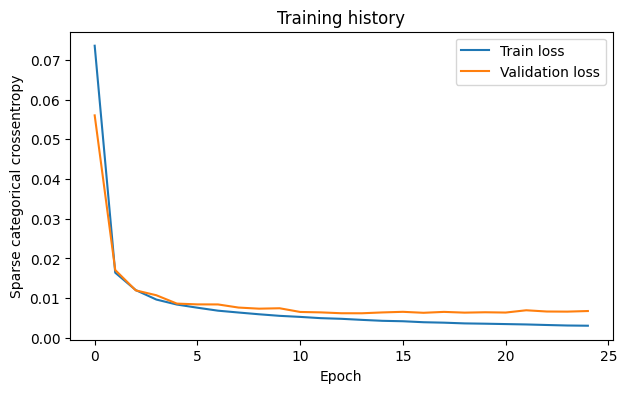

In [24]:
# Learning curves (useful for the discussion: over/underfitting)
plt.figure(figsize=(7, 4))
plt.plot(history.history["loss"], label="Train loss")
plt.plot(history.history["val_loss"], label="Validation loss")
plt.xlabel("Epoch"); plt.ylabel("Sparse categorical crossentropy"); plt.title("Training history")
plt.legend(); plt.show()

**5. Obtain predictions and performance metrics (1.5 point)**

*   Generate predictions for all images in the validation set
*   The mask is determined by the maximum value along the final axis. For all the predictions get the value of the predicted mask.
*   Use the test mask images to compare with the results (get_mask method of the generator class): Find the DICE similarity score for the test/validation set.
Here is a function to calculate the value

```python
def dice_coef(y_true, y_pred, smooth=1):
    y_true_f = K.flatten(y_true)
    y_pred_f = K.flatten(y_pred)
    intersection = K.sum(y_true_f * y_pred_f)
    return (2. * intersection + smooth) / (K.sum(y_true_f) + K.sum(y_pred_f) + smooth)

```

In [25]:
#solution

model = keras.models.load_model("covid_infection_unet.keras")

val_preds  = model.predict(val_gen)                               # (N, 128, 128, 2) probabilities
pred_masks = np.argmax(val_preds, axis=-1)[..., np.newaxis]       # (N, 128, 128, 1) class with max probability
true_masks = val_gen.get_masks()                                  # (N, 128, 128, 1)
print(val_preds.shape, pred_masks.shape, true_masks.shape)

def dice_coef(y_true, y_pred, smooth=1):
    y_true_f = tf.reshape(tf.cast(y_true, tf.float32), [-1])
    y_pred_f = tf.reshape(tf.cast(y_pred, tf.float32), [-1])
    intersection = tf.reduce_sum(y_true_f * y_pred_f)
    return float((2.0 * intersection + smooth) /
                 (tf.reduce_sum(y_true_f) + tf.reduce_sum(y_pred_f) + smooth))

print("Dice (whole validation set):", round(dice_coef(true_masks, pred_masks), 4))

44/44 ━━━━━━━━━━━━━━━━━━━━ 10s 13ms/step
(352, 128, 128, 2) (352, 128, 128, 1) (352, 128, 128, 1)
Dice (whole validation set): 0.8313


In [26]:
# Complementary views of the same prediction
print("Jaccard per class [background, infection]:",
      jaccard_score(true_masks.ravel(), pred_masks.ravel(), average=None))
print("Jaccard micro   :", jaccard_score(true_masks.ravel(), pred_masks.ravel(), average="micro"))
print("Jaccard macro   :", jaccard_score(true_masks.ravel(), pred_masks.ravel(), average="macro"))
print("Pixel accuracy  :", (true_masks == pred_masks).mean())

# Slice-level Dice, only on slices that really contain infection
has_inf = true_masks.reshape(len(true_masks), -1).max(1) > 0
slice_dice = [dice_coef(t, p) for t, p in zip(true_masks[has_inf], pred_masks[has_inf])]
print("Mean Dice over infected slices:", round(float(np.mean(slice_dice)), 4), "on", has_inf.sum(), "slices")

Jaccard per class [background, infection]: [0.99752065 0.71133769]
Jaccard micro   : 0.9950835267704251
Jaccard macro   : 0.8544291713991695
Pixel accuracy  : 0.9975357055664062
Mean Dice over infected slices: 0.7663 on 180 slices


*   Is this model performing well?
*   What are other evaluation metrics to compare the performance of segmentation? Which parameter is used for what type of problem?
*   What do you understand from the 'average' parameter of the similarity score function?

**Solution**

* *Is the model performing well?* Judge it with the Dice/Jaccard of the **infection class**, never with pixel accuracy: infected
  pixels are only a few percent of the image, so a model that predicts "all background" already gets ~95%+ accuracy but Dice = 0.
  Report the Dice from the cell above and compare it with that trivial baseline. Also mention that the split is by slice, so the
  score is likely optimistic, and that only 20 patients are available.

* *Other segmentation metrics:* **IoU / Jaccard** = TP/(TP+FP+FN), stricter than Dice (Dice = 2·IoU/(1+IoU)); **Dice / F1** = 2TP/(2TP+FP+FN), standard
  for medical images with small structures and class imbalance; **precision / recall (sensitivity)**, where recall matters when missing
  an infection is costly; **pixel accuracy**, only fine for balanced classes; **Hausdorff distance**, which measures boundary error and is used
  when contours matter (surgery/radiotherapy planning); **mean IoU**, the usual metric for multi-class benchmarks (Pets, Cityscapes).
  
* *The `average` parameter (sklearn):* `None` returns one score per class; `binary` scores only the positive class; `macro` is the unweighted mean of
  class scores (treats the rare class as important as the large one); `weighted` weights classes by their support; `micro` pools all TP/FP/FN
  across classes, so on a dominant background it is dominated by the background and looks deceptively high.

...

**6. Display one image with infection: Its CT, overlayed groundtruth mask, overlayed prediction mask using matplotlib (3 images) (1 point)**

<img src="https://drive.google.com/uc?export=view&id=1P6UXNyLNin2nwTWJw0-2RqnX3uuerkfh">

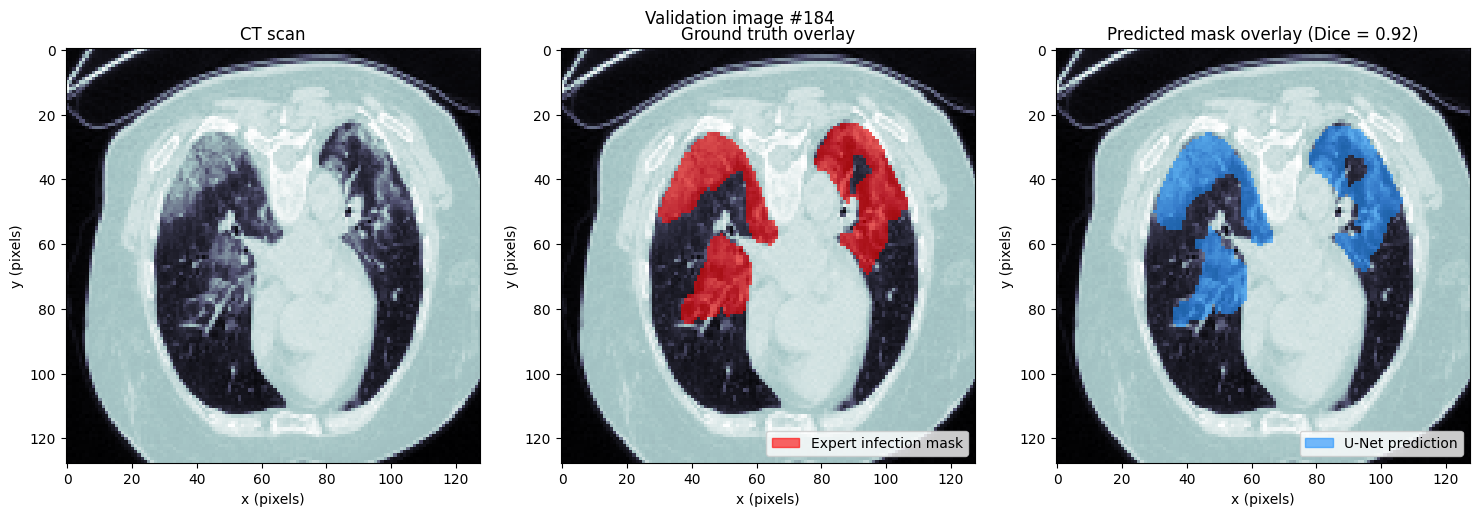

In [27]:
#solution

def plot_prediction(ct_img, true_mask, pred_mask, idx_label=""):
    """3 panels: CT, ground truth overlay (red), prediction overlay (blue)."""
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    ct_2d = ct_img.squeeze()
    d = dice_coef(true_mask, pred_mask)

    axes[0].imshow(ct_2d, cmap="bone"); axes[0].set_title("CT scan")

    axes[1].imshow(ct_2d, cmap="bone")
    axes[1].imshow(np.ma.masked_where(true_mask.squeeze() == 0, true_mask.squeeze()),
                   cmap=ListedColormap(["red"]), alpha=0.6)
    axes[1].set_title("Ground truth overlay")
    axes[1].legend(handles=[Patch(color="red", alpha=0.6, label="Expert infection mask")], loc="lower right")

    axes[2].imshow(ct_2d, cmap="bone")
    axes[2].imshow(np.ma.masked_where(pred_mask.squeeze() == 0, pred_mask.squeeze()),
                   cmap=ListedColormap(["dodgerblue"]), alpha=0.6)
    axes[2].set_title(f"Predicted mask overlay (Dice = {d:.2f})")
    axes[2].legend(handles=[Patch(color="dodgerblue", alpha=0.6, label="U-Net prediction")], loc="lower right")

    for ax in axes:
        ax.set_xlabel("x (pixels)"); ax.set_ylabel("y (pixels)")
    fig.suptitle(f"Validation image {idx_label}")
    plt.tight_layout(); plt.show()

# pick a validation slice that really has infection (here: the one with the most infected pixels)
infected_pixels = true_masks.reshape(len(true_masks), -1).sum(1)
idx = int(np.argmax(infected_pixels))
plot_prediction(X_val[idx], true_masks[idx], pred_masks[idx], idx_label=f"#{idx}")

**7. To think further... Theoretical questions (1 point)**

*   What is the difference between instance segmentation and semantic segmentation?

**Solution**

**Instance vs semantic segmentation.** Semantic segmentation assigns a class to every pixel but does not separate objects of the same
class (two infected areas or two dogs are one "dog" region). Instance segmentation also separates each individual object
(dog 1, dog 2), e.g. Mask R-CNN. Panoptic segmentation combines both.

...

*   What is the difference between encoder and decoder? Should they be of the same type of neural network?

**Solution**

**Encoder vs decoder; same network type?** The encoder (downsampling path) extracts increasingly abstract features while shrinking spatial
resolution (convs + pooling/strides). The decoder (upsampling path) recovers spatial resolution and turns features into a per-pixel
prediction (transposed convs/upsampling). They do not have to be the same type: the encoder is often a pretrained classification backbone
(ResNet, EfficientNet) with a lighter decoder; in practice they are usually mirrored for symmetry.

...

*   What are feature channels in UNet? Why is this helpful in this architecture?

**Solution**

**Feature channels in a U-Net.** The channel dimension is the number of feature maps per layer (32, 64, 128, 256 here). Early layers capture simple patterns
(edges, textures), deeper layers capture complex ones, so channels increase as resolution decreases. In the original U-Net, skip connections concatenate encoder feature
maps with decoder ones, combining *what* (deep semantics) with *where* (fine spatial detail) and so producing sharp boundaries. The tutorial
model is "U-Net-like": it adds residuals instead of concatenating.

...

*   What are the other popular semantic segmentation algorithms?
*   How are they different from each other?

**Solution**

**Other semantic segmentation algorithms.** FCN (first fully-convolutional approach, coarse output), SegNet (encoder-decoder using pooling indices), DeepLab v3+ (atrous
convolutions + ASPP for multi-scale context), PSPNet (pyramid pooling), U-Net++ / Attention U-Net / nnU-Net (medical variants), and transformer-based
SegFormer / Swin-UNet / SAM-like foundation models. Differences: how they preserve resolution (skips, atrous convs, pooling indices), how they capture context
(pyramid pooling, attention) and cost/accuracy trade-off.

...

*   What are the popular semantic segmentation datasets which are available for public access?

**Solution**

**Public datasets.** Pascal VOC, MS COCO, Cityscapes, ADE20K, Oxford-IIIT Pet (the tutorial); medical: BraTS (brain tumours), ISIC (skin lesions),
LiTS (liver), Medical Segmentation Decathlon, and this COVID-19 CT set.

...


---

## **End of Image Segmentation using UNet**